# ST1131 Introduction to Statistics and Statistical Computing
## Topic 7 (Confidence Intervals)

In the lecture, we learnt how to estimate a population parameter with a point estimate, and how a confidence interval (CI) gives a range of believable values for the parameter. In this notebook, we will use Python to find multipliers (quantile values), compute confidence intervals for a population proportion $p$ and a population mean $\mu$, determine the sample size needed for a target width, and use simulation to see what the confidence level really means.

Every confidence interval in this topic has the same form:

$$\text{point estimate}\pm\text{multiplier}\times\text{standard error}.$$

So in Python, we only ever need three ingredients: the point estimate, the multiplier, and the standard error.

## Packages

We will use `numpy` for calculations and simulations, `matplotlib` for plots, and two distributions from `scipy.stats`: `norm` (Topic 5) and `t`, the $t$-distribution, which is new in this topic. We also import `math` for rounding up sample sizes.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm, t

### Caution with the name $t$

Since we imported the $t$-distribution as `t`, we must not create a variable called `t` (for example `t = 5`) in this notebook. Doing so would replace the t-distribution, and any later code using `t.ppf` would fail, so we use names like `t_mult` instead.

## Point estimates

A point estimate is a single number that is our best guess for a population parameter. We use the sample proportion $\hat{p}$ to estimate $p$, and the sample mean $\bar{x}$ to estimate $\mu$.

In the breast cancer example, 79 of 200 post-menopausal hormone users developed breast cancer, so the point estimate of $p$ is:

In [2]:
p_hat = 79/200
print(f"Point estimate of p: {p_hat}")

Point estimate of p: 0.395


A point estimate on its own does not tell us how close it is likely to be to the true value. A different sample would give a different $\hat{p}$, which is why we form an interval around it.

## Finding the multiplier

For a $100(1-\alpha)\%$ confidence interval for $p$, the multiplier is the quantile $q_{1-\alpha/2}$ of $N(0,1)$. In Topic 5, we learnt that `.ppf` finds quantiles, so the multiplier for a 95% CI ($\alpha=0.05$) is:

In [3]:
conf_level = 0.95
alpha = 1-conf_level
z_mult = norm.ppf(1-alpha/2) #quantile for probability 0.975
print(f"Multiplier: {round(z_mult, 4)}")

Multiplier: 1.96


We use $1-\alpha/2$ and not $1-\alpha$ because the remaining probability $\alpha$ is split equally between the two tails. For a 95% CI, 2.5% is in each tail, so we need the value with 97.5% of the area to its left.

Using a `for` loop, we can find the multipliers for several confidence levels at once. Notice that the multiplier increases with the confidence level.

In [4]:
for conf_level in [0.80, 0.90, 0.95, 0.99]:
    alpha = 1-conf_level
    print(f"{int(conf_level*100)}% CI: multiplier = {round(norm.ppf(1-alpha/2), 4)}")

80% CI: multiplier = 1.2816
90% CI: multiplier = 1.6449
95% CI: multiplier = 1.96
99% CI: multiplier = 2.5758


The lecture rounds these multipliers to 1.28, 1.645, 1.96 and 2.58. Python uses the exact values, so our answers may differ slightly from the lecture in the last decimal place.

## Confidence interval for a population proportion

The $100(1-\alpha)\%$ CI for $p$ is

$$\hat{p}\pm q_{1-\alpha/2}\times\sqrt{\frac{\hat{p}(1-\hat{p})}{n}},$$

which is valid when $n\hat{p}(1-\hat{p})\ge5$.

### Election example

In a random sample of $n=3889$ voters, the proportion voting for Jerry Brown was $\hat{p}=0.531$. Following the general procedure from the lecture, we first check the condition, then compute the standard error and the 95% CI.

In [5]:
n = 3889
p_hat = 0.531

print(f"n*p_hat*(1-p_hat): {round(n*p_hat*(1-p_hat), 2)}") #should be at least 5

se = np.sqrt(p_hat*(1-p_hat)/n) #standard error
z_mult = norm.ppf(0.975) #multiplier for a 95% CI
moe = z_mult*se #margin of error

lower = p_hat-moe
upper = p_hat+moe

print(f"Standard error: {round(se, 4)}")
print(f"Margin of error: {round(moe, 4)}")
print(f"95% CI: ({round(lower, 3)}, {round(upper, 3)})")

n*p_hat*(1-p_hat): 968.51
Standard error: 0.008
Margin of error: 0.0157
95% CI: (0.515, 0.547)


We are 95% confident that the proportion of voters voting for Brown is between 0.515 and 0.547. Since the whole interval is above 0.5, we are 95% confident that Brown is winning the election.

### Effect of the confidence level

Let's repeat this for the 80%, 95% and 99% CIs from the lecture. Only the multiplier changes, since the point estimate and standard error stay the same.

In [6]:
for conf_level in [0.80, 0.95, 0.99]:
    alpha = 1-conf_level
    z_mult = norm.ppf(1-alpha/2)
    lower = p_hat-z_mult*se
    upper = p_hat+z_mult*se
    print(f"{int(conf_level*100)}% CI: ({round(lower, 3)}, {round(upper, 3)}), width = {round(upper-lower, 4)}")

80% CI: (0.521, 0.541), width = 0.0205
95% CI: (0.515, 0.547), width = 0.0314
99% CI: (0.51, 0.552), width = 0.0412


We can see the intervals side by side with `plt.errorbar`, which draws a point with a bar on each side. The `xerr` argument is the length of each bar, which is the margin of error. You do not need to learn how to plot this, it is for visualising only.

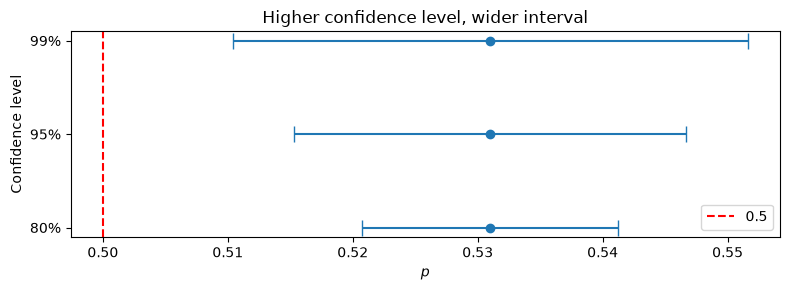

In [7]:
levels = [0.80, 0.95, 0.99]
moes = [norm.ppf(1-(1-c)/2)*se for c in levels] #margin of error for each level

plt.figure(figsize=(8,3))
plt.errorbar(x=[p_hat]*3, y=[0,1,2], xerr=moes, fmt="o", color="tab:blue", capsize=6)
plt.axvline(0.5, color="red", linestyle="--", label="0.5")
plt.yticks([0,1,2], ["80%", "95%", "99%"])
plt.xlabel(r"$p$")
plt.ylabel("Confidence level")
plt.title("Higher confidence level, wider interval")
plt.legend()
plt.tight_layout()
plt.show()

The line `[p_hat]*3` repeats the list `[p_hat]` three times, giving `[0.531, 0.531, 0.531]`, since all three intervals are centred at the same point estimate.

### Effect of the sample size

Suppose the same $\hat{p}=0.531$ came from a sample of only $n=50$ voters. The standard error is much larger, so the 99% CI is much wider.

In [8]:
z_mult = norm.ppf(0.995) #multiplier for a 99% CI

for n in [3889, 50]:
    se = np.sqrt(p_hat*(1-p_hat)/n)
    lower = p_hat-z_mult*se
    upper = p_hat+z_mult*se
    print(f"n = {n}: 99% CI = ({round(lower, 3)}, {round(upper, 3)})")

n = 3889: 99% CI = (0.51, 0.552)
n = 50: 99% CI = (0.349, 0.713)


With $n=50$, the interval includes values below 0.5, so we can no longer be confident that Brown is winning.

### A shortcut with norm.interval

Instead of computing the margin of error ourselves, we can use `norm.interval(conf_level, loc, scale)`. It returns the interval containing the middle `conf_level` of the area under a normal curve, so we set `loc` to the point estimate and `scale` to the standard error. Both values are returned together, so we store them in two variables.

In [9]:
n = 3889
se = np.sqrt(p_hat*(1-p_hat)/n)

lower, upper = norm.interval(0.95, loc=p_hat, scale=se)
print(f"95% CI: ({round(lower, 3)}, {round(upper, 3)})")

95% CI: (0.515, 0.547)


We recommend computing the interval step by step first, as it shows clearly where each part of the formula comes from. The shortcut is useful for checking your answer.

## What does 95% confidence mean?

From the lecture, the confidence level describes the method over many samples. If we collected many samples and formed a 95% CI from each one, then in the long run, about 95% of the intervals would contain the true value of $p$. In real life we only have one sample, but with simulation we can collect as many samples as we like.

Suppose the true proportion is $p=0.531$, and we repeatedly survey $n=200$ voters. As in Topic 6, `np.random.binomial` gives the number of Brown voters in each sample, and dividing by $n$ gives $\hat{p}$. All the intervals are computed at once using arrays.

In [10]:
np.random.seed(7)

p = 0.531 #the true proportion, which is unknown in real life
n = 200
N = 100 #number of samples

p_hats = np.random.binomial(n, p, size=N)/n
ses = np.sqrt(p_hats*(1-p_hats)/n)
lowers = p_hats-norm.ppf(0.975)*ses
uppers = p_hats+norm.ppf(0.975)*ses

covers = (lowers <= p) & (p <= uppers) #True if the interval contains p
print(f"Number of intervals containing p: {np.sum(covers)} out of {N}")

Number of intervals containing p: 93 out of 100


We plot each interval as a horizontal line, in blue if it contains the true $p$ and in red if it misses. The `for` loop draws one interval at a time, and `range(N)` gives the numbers $0,1,\dots,N-1$, which we use as the height of each line.

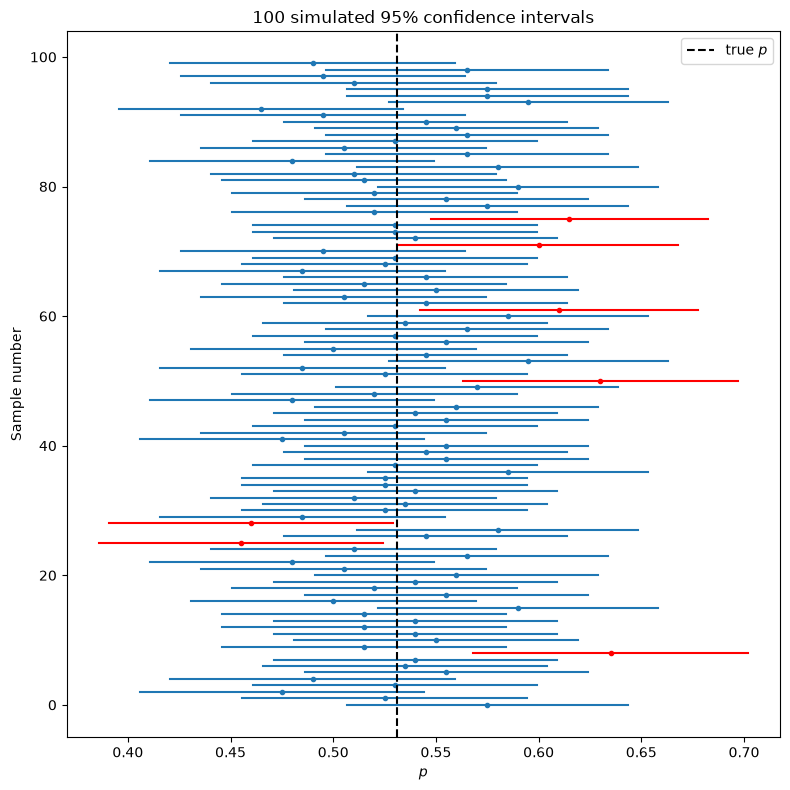

In [11]:
plt.figure(figsize=(8,8))
for i in range(N):
    colour = "tab:blue" if covers[i] else "red"
    plt.plot([lowers[i], uppers[i]], [i, i], color=colour)
    plt.plot(p_hats[i], i, "o", color=colour, markersize=3)
plt.axvline(p, color="black", linestyle="--", label=r"true $p$")
plt.xlabel(r"$p$")
plt.ylabel("Sample number")
plt.title("100 simulated 95% confidence intervals")
plt.legend()
plt.tight_layout()
plt.show()

The line `colour = "tab:blue" if covers[i] else "red"` is a short way of writing an `if`/`else` statement on one line.

Each sample gives a different interval. Most of them contain $p$, but a few miss. Any single interval either contains $p$ or it does not, and the 95% refers to how often the method succeeds. With 10,000 samples, the proportion of intervals that contain $p$ is close to 0.95. Note that `np.mean` of a boolean array gives the proportion of `True` values.

In [12]:
N = 10000
p_hats = np.random.binomial(n, p, size=N)/n
ses = np.sqrt(p_hats*(1-p_hats)/n)
lowers = p_hats-norm.ppf(0.975)*ses
uppers = p_hats+norm.ppf(0.975)*ses

print(f"Proportion of 95% CIs containing p: {np.mean((lowers <= p) & (p <= uppers))}")

Proportion of 95% CIs containing p: 0.9442


The proportion is slightly below 0.95 because this CI relies on the normal approximation to the sampling distribution of $\hat{p}$, so the confidence level of 95% is approximate. The approximation improves as $n$ increases.

## Determining the sample size for a proportion

Suppose we want a $100(1-\alpha)\%$ CI for $p$ with width at most $D$. From the lecture, we need

$$n\ge\left(\frac{2q_{1-\alpha/2}}{D}\right)^2p(1-p).$$

When $p$ is unknown, we use $p=0.5$. The plot below shows why: $p(1-p)$ is largest at $p=0.5$, so using 0.5 gives the largest (safest) sample size.

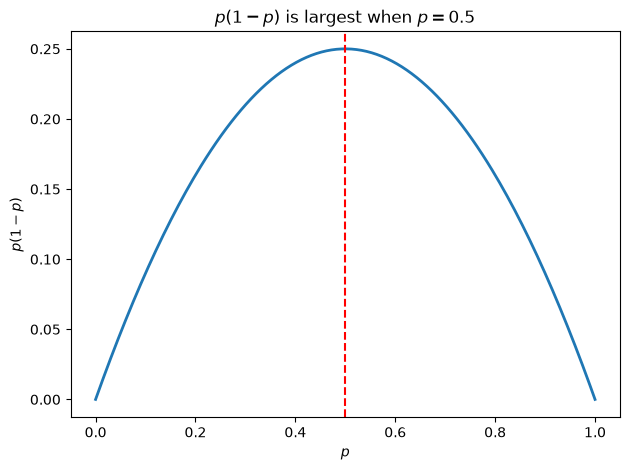

In [13]:
ps = np.linspace(0,1,200)

plt.figure()
plt.plot(ps, ps*(1-ps), color="tab:blue", linewidth=2)
plt.axvline(0.5, color="red", linestyle="--")
plt.xlabel(r"$p$")
plt.ylabel(r"$p(1-p)$")
plt.title(r"$p(1-p)$ is largest when $p=0.5$")
plt.tight_layout()
plt.show()

In the election polling example, we want a 95% CI with width at most $D=0.1$. Since $n$ must be a whole number and must be at least the value we calculate, we always round **up**, using `math.ceil` (short for "ceiling").

In [14]:
D = 0.1
z_mult = norm.ppf(0.975)

n_needed = (2*z_mult/D)**2*0.5*(1-0.5)
print(f"n must be at least: {round(n_needed, 2)}")
print(f"Sample size needed: {math.ceil(n_needed)}")

n must be at least: 384.15
Sample size needed: 385


We need to survey at least 385 people. Take note that `round` would give 384, which is too small, since $384<384.15$.

## The $t$-distribution

For a population mean $\mu$, the population standard deviation $\sigma$ is usually unknown, so we replace it with the sample standard deviation $s$. From the lecture, this gives

$$\frac{\bar{X}-\mu}{s/\sqrt{n}}\sim t_{n-1},$$

a $t$-distribution with $n-1$ degrees of freedom ($df$). In `scipy.stats`, the $t$-distribution works like `norm`, except that we must give the degrees of freedom: `t.pdf(x, df)`, `t.cdf(x, df)` and `t.ppf(q, df)`.

### Comparing the $t$-distribution with N(0, 1)

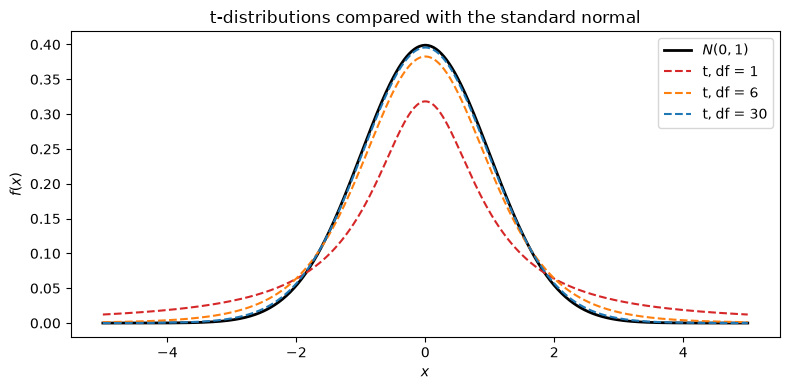

In [15]:
xs = np.linspace(-5,5,500)

plt.figure(figsize=(8,4))
plt.plot(xs, norm.pdf(xs), color="black", linewidth=2, label=r"$N(0,1)$")
for df, colour in zip([1,6,30], ["tab:red", "tab:orange", "tab:blue"]):
    plt.plot(xs, t.pdf(xs, df), color=colour, linestyle="--", label=f"t, df = {df}")
plt.xlabel(r"$x$")
plt.ylabel(r"$f(x)$")
plt.title("t-distributions compared with the standard normal")
plt.legend()
plt.tight_layout()
plt.show()

Like $N(0,1)$, the $t$-distribution is symmetric about 0, but it has thicker tails. As the degrees of freedom increase, it gets closer to $N(0,1)$, and with $df$ = 30 the two curves are almost identical.

### Quantiles of the t-distribution

The thicker tails mean that the $t$ multiplier is larger than the normal multiplier of 1.96, especially for small $df$. Let's check the values from the lecture.

In [16]:
for df in [6, 46, 1000]:
    print(f"df = {df}: t quantile for 0.975 = {round(t.ppf(0.975, df), 4)}")

print(f"N(0,1) quantile for 0.975 = {round(norm.ppf(0.975), 4)}")

df = 6: t quantile for 0.975 = 2.4469
df = 46: t quantile for 0.975 = 2.0129
df = 1000: t quantile for 0.975 = 1.9623
N(0,1) quantile for 0.975 = 1.96


## Confidence interval for a population mean

The $100(1-\alpha)\%$ CI for $\mu$ is

$$\bar{x}\pm t_{n-1,1-\alpha/2}\times\frac{s}{\sqrt{n}},$$

which requires a sample obtained by randomization, and a data distribution that is approximately normal or symmetric.

### Baby weights example (from summary statistics)

A random sample of $n=47$ babies born in August has sample mean $\bar{x}=3.208$ kg and sample standard deviation $s=0.506$ kg. When we are only given summary statistics, we can use them directly.

In [17]:
n = 47
x_bar = 3.208
s = 0.506

se = s/np.sqrt(n) #standard error
t_mult = t.ppf(0.975, df=n-1) #df = 46
moe = t_mult*se

print(f"Standard error: {round(se, 4)}")
print(f"Multiplier: {round(t_mult, 4)}")
print(f"95% CI: ({round(x_bar-moe, 2)}, {round(x_bar+moe, 2)})")

Standard error: 0.0738
Multiplier: 2.0129
95% CI: (3.06, 3.36)


We are 95% confident that the interval (3.06, 3.36) contains the true mean weight of babies born in August.

### Working with raw data

More often, we are given the data itself rather than the summary statistics. We then need to check the assumptions and compute $\bar{x}$ and $s$ ourselves. To illustrate, we simulate a sample of 47 baby weights. Remember from Topic 1 that `ddof=1` gives the **sample** standard deviation $s$, which is what the formula needs.

In [18]:
np.random.seed(47)

weights = np.round(np.random.normal(3.2, 0.5, size=47), 2) #a simulated sample of 47 baby weights (kg)
print(weights[:10])

n = len(weights)
x_bar = np.mean(weights)
s = np.std(weights, ddof=1) #sample standard deviation

print(f"n: {n}")
print(f"Sample mean: {round(x_bar, 4)}")
print(f"Sample SD: {round(s, 4)}")

[2.78 3.85 3.66 3.52 2.67 4.1  2.69 3.61 3.05 2.9 ]
n: 47
Sample mean: 3.0994
Sample SD: 0.4901


Before computing the CI, we check the shape of the data with a histogram. The data look roughly symmetric with no extreme outliers, so the method is appropriate.

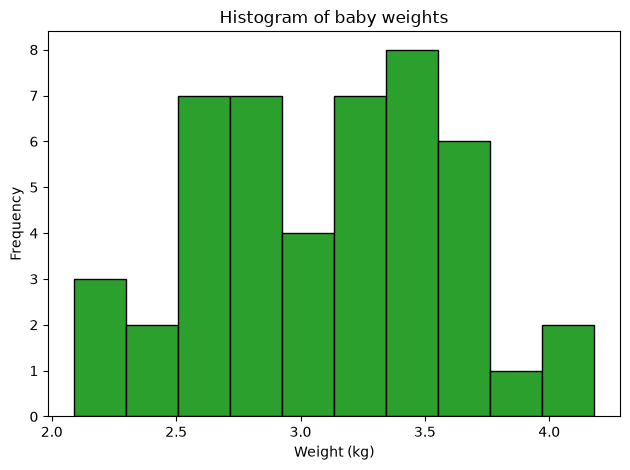

In [19]:
plt.figure()
plt.hist(weights, bins=10, color="tab:green", edgecolor="black")
plt.xlabel("Weight (kg)")
plt.ylabel("Frequency")
plt.title("Histogram of baby weights")
plt.tight_layout()
plt.show()

In [20]:
se = s/np.sqrt(n)
t_mult = t.ppf(0.975, df=n-1)

lower = x_bar-t_mult*se
upper = x_bar+t_mult*se
print(f"95% CI: ({round(lower, 3)}, {round(upper, 3)})")

lower, upper = t.interval(0.95, df=n-1, loc=x_bar, scale=se) #shortcut, to check
print(f"95% CI using t.interval: ({round(lower, 3)}, {round(upper, 3)})")

95% CI: (2.955, 3.243)
95% CI using t.interval: (2.955, 3.243)


Just like `norm.interval`, the shortcut `t.interval` takes the confidence level, the degrees of freedom, the point estimate as `loc`, and the standard error as `scale`.

### Why do we need the $t$-distribution?

What if we ignored the $t$-distribution and used the normal multiplier 1.96 with $s$? Let's check with a simulation, using the midterm example from Topic 6, $N(70,10^2)$, with a small sample size of $n=5$. We form 10,000 intervals each way and count how often they contain $\mu=70$. As in Topic 6, each row of the 2D array is one sample.

In [21]:
np.random.seed(2026)

mu = 70
sigma = 10
n = 5
N = 10000

samples = np.random.normal(mu, sigma, size=(N, n))
x_bars = samples.mean(axis=1)
ses = samples.std(axis=1, ddof=1)/np.sqrt(n) #s/sqrt(n) for each sample

for name, mult in [("normal, 1.96", norm.ppf(0.975)), ("t, df = 4", t.ppf(0.975, df=n-1))]:
    covers = (x_bars-mult*ses <= mu) & (mu <= x_bars+mult*ses)
    print(f"Multiplier {name} ({round(mult, 3)}): proportion containing mu = {np.mean(covers)}")

Multiplier normal, 1.96 (1.96): proportion containing mu = 0.876
Multiplier t, df = 4 (2.776): proportion containing mu = 0.9493


With the normal multiplier, the intervals are too narrow and contain $\mu$ only about 88% of the time, even though we call them 95% CIs. The $t$ multiplier accounts for the extra uncertainty from estimating $\sigma$ with $s$, and gives the correct 95%. For large $n$, the two multipliers are nearly the same, so the difference only matters for small samples.

### Factors affecting the width

The width of the CI is $2\times t_{n-1,1-\alpha/2}\times s/\sqrt{n}$. Keeping $s=0.506$ from the baby weights example, we can see how the width changes with $n$ and with the confidence level.

In [22]:
s = 0.506

for n in [10, 47, 200]:
    for conf_level in [0.90, 0.95, 0.99]:
        t_mult = t.ppf(1-(1-conf_level)/2, df=n-1)
        width = 2*t_mult*s/np.sqrt(n)
        print(f"n = {n}, {int(conf_level*100)}% CI: width = {round(width, 4)}")
    print()

n = 10, 90% CI: width = 0.5866
n = 10, 95% CI: width = 0.7239
n = 10, 99% CI: width = 1.04

n = 47, 90% CI: width = 0.2478
n = 47, 95% CI: width = 0.2971
n = 47, 99% CI: width = 0.3966

n = 200, 90% CI: width = 0.1183
n = 200, 95% CI: width = 0.1411
n = 200, 99% CI: width = 0.1861



For each sample size, a higher confidence level gives a wider interval. For each confidence level, a larger sample size gives a narrower interval. A larger population variance would also give a wider interval, but that is usually out of our control.

## Determining the sample size for a mean

For a $100(1-\alpha)\%$ CI for $\mu$ with width at most $D$, the lecture gives

$$n\ge\left(\frac{2q_{1-\alpha/2}\times s}{D}\right)^2,$$

where we use the normal quantile (since we do not know $n$, and so do not know the df), and $s$ comes from a pilot study or a similar study.

In the new baby weights study, we want a 95% CI with width at most 0.2, using the pilot estimate $s=0.5064$.

In [23]:
D = 0.2
s = 0.5064
z_mult = norm.ppf(0.975)

n_needed = (2*z_mult*s/D)**2
print(f"n must be at least: {round(n_needed, 2)}")
print(f"Sample size needed: {math.ceil(n_needed)}")

n must be at least: 98.51
Sample size needed: 99


We need a sample of at least 99 babies. Since $99\ge30$, the normal quantile was a reasonable approximation for the t quantile.

## Summary of Python tools in this topic

| Task | Code |
|---|---|
| Multiplier for a CI for $p$ | `norm.ppf(1-alpha/2)` |
| Multiplier for a CI for $\mu$ | `t.ppf(1-alpha/2, df=n-1)` |
| Standard error of $\hat{p}$ | `np.sqrt(p_hat*(1-p_hat)/n)` |
| Standard error of $\bar{x}$ | `s/np.sqrt(n)`, with `s = np.std(data, ddof=1)` |
| CI shortcut for $p$ | `norm.interval(conf_level, loc=p_hat, scale=se)` |
| CI shortcut for $\mu$ | `t.interval(conf_level, df=n-1, loc=x_bar, scale=se)` |
| Round up a sample size | `math.ceil(n_needed)` |